# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
# Add code here 🔧

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(url)

print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

df.head()

Shape: 119,390 rows x 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The dataset has 119,390 rows and 32 columns. Some ADRs are zero which is unusual. Each row has 0 for cancellations which is also unusual. Also, lead time ranges from 7 days to over 700 days.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
# Add code here 🔧

df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

features = ["lead_time", "total_nights", "adr", "total_of_special_requests"]

df["children"] = df["children"].fillna(0).astype(int)

df["agent"] = df["agent"].astype("Int64").astype(str)
df["company"] = df["company"].astype("Int64").astype(str)

clean = df.dropna(subset=features).copy()

before = len(clean)
clean = clean.drop_duplicates()
print(f"Duplicates removed: {before - len(clean):,}")

clean = clean[(clean["adults"] > 0) & (clean["total_nights"] > 0) & (clean["adr"] > 0)]

def iqr_filter(data, cols, k=1.5):
    mask = pd.Series(True, index=data.index)
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        mask &= data[c].between(q1 - k * iqr, q3 + k * iqr)
    return data[mask]

before = len(clean)
clean = iqr_filter(clean, ["lead_time", "total_nights", "adr"])
print(f"Outliers removed: {before - len(clean):,}")
print(f"Final shape: {clean.shape}")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(clean[features])
X_scaled = pd.DataFrame(X_scaled, columns=features, index=clean.index)

X_scaled.describe().round(2)

Duplicates removed: 31,994
Outliers removed: 7,412
Final shape: (77961, 33)


,lead_time,total_nights,adr,total_of_special_requests
count,77961.00,77961.00,77961.00,77961.00
mean,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00
min,-0.98,-1.18,-2.40,-0.84
25%,-0.83,-0.67,-0.71,-0.84
50%,-0.35,-0.15,-0.14,-0.84
75%,0.60,0.36,0.62,0.37
max,3.11,2.94,2.82,5.22


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. I chose lead time , total nights, adr, and special requests. All together they capture planning behavior, trip length, spending level, and service expectations. All are numeric, directly describe guest behavior, and are all free of leakage.

2. Some segments I expect are last-minute, short-stay guest who book with little lead time or budget-conscious guests with low adr, few requests, who respond to pricing promotions.


## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

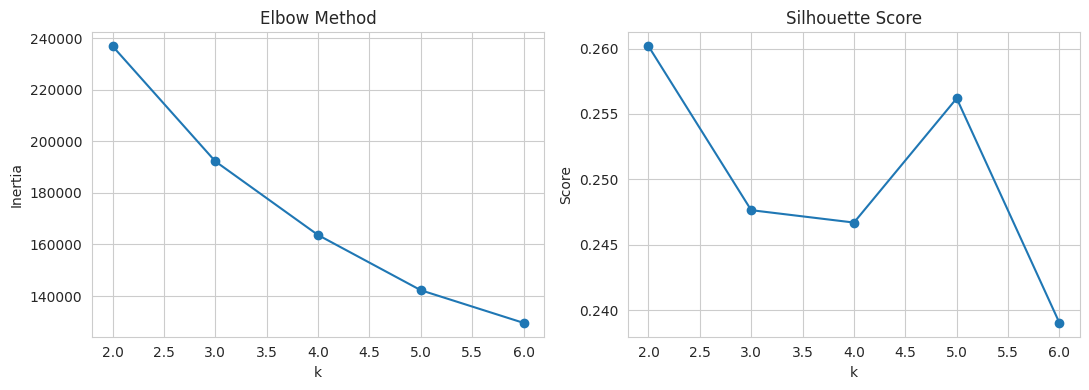

kmeans_cluster
0    19409
1    29404
2    11476
3    17672
Name: count, dtype: int64


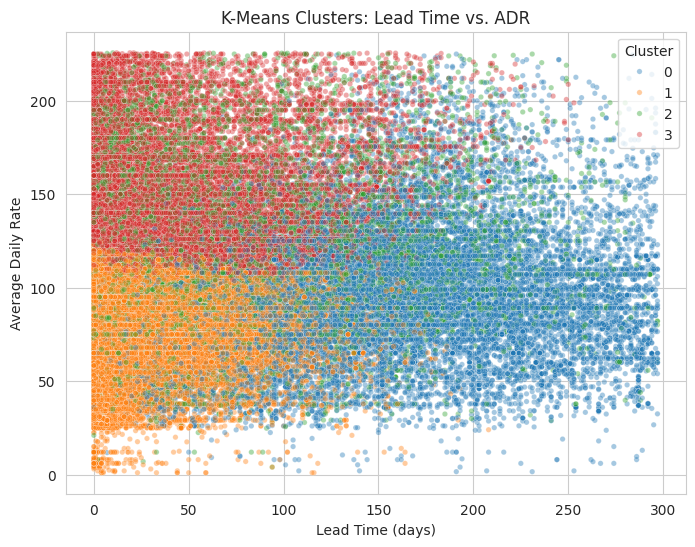

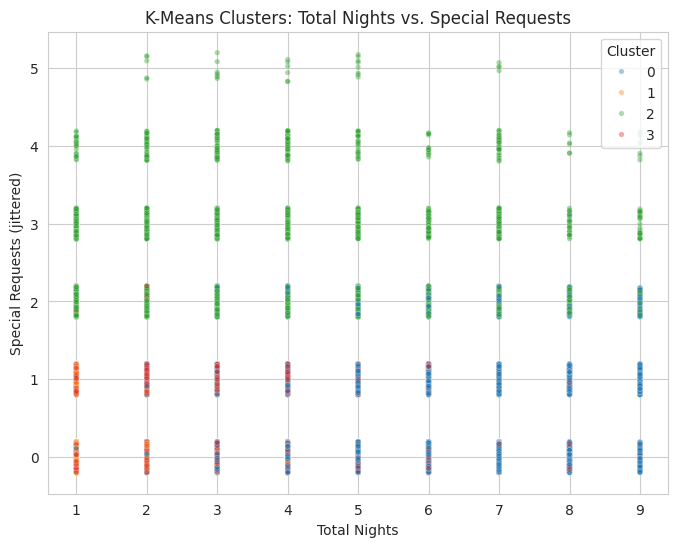

,lead_time,total_nights,adr,total_of_special_requests,guests,pct_of_guests
kmeans_cluster,,,,,,
0,157.88,5.08,96.79,0.51,19409,24.9
1,29.23,2.31,74.90,0.35,29404,37.7
2,68.89,3.34,118.77,2.22,11476,14.7
3,47.74,2.96,152.62,0.48,17672,22.7


In [3]:
# Add code here 🔧

inertias, sils = [], []
k_range = range(2, 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_scaled, labels, sample_size=10000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(k_range, inertias, marker="o")
ax[0].set(title="Elbow Method", xlabel="k", ylabel="Inertia")
ax[1].plot(k_range, sils, marker="o")
ax[1].set(title="Silhouette Score", xlabel="k", ylabel="Score")
plt.tight_layout()
plt.show()

k = 4
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

clean["kmeans_cluster"] = kmeans.fit_predict(X_scaled)
print(clean["kmeans_cluster"].value_counts().sort_index())

plt.figure(figsize=(8, 6))
sns.scatterplot(data=clean, x="lead_time", y="adr", hue="kmeans_cluster",
                palette="tab10", alpha=0.4, s=15)
plt.title("K-Means Clusters: Lead Time vs. ADR")
plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate")
plt.legend(title="Cluster")
plt.show()

plot_df = clean.copy()
plot_df["requests_jitter"] = plot_df["total_of_special_requests"] + np.random.uniform(-0.2, 0.2, len(plot_df))
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="total_nights", y="requests_jitter", hue="kmeans_cluster",
                palette="tab10", alpha=0.4, s=15)
plt.title("K-Means Clusters: Total Nights vs. Special Requests")
plt.xlabel("Total Nights")
plt.ylabel("Special Requests (jittered)")
plt.legend(title="Cluster")
plt.show()

summary = clean.groupby("kmeans_cluster")[features].mean().round(2)
summary["guests"] = clean["kmeans_cluster"].value_counts().sort_index()
summary["pct_of_guests"] = (summary["guests"] / len(clean) * 100).round(1)
summary

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. I tested k =2 through 6 using intertia and silhouette score. The elbow plot declined gradually with no bend. Silhouette scores remained consistent. I chose k=4 because its silhouette score was close to the best options, and it gives the marketing manager four groups that are large enough to justify a campaign.

2. Cluster 0: early planning vacationers, 24.9%. Longest lead time ofg 158 days with the longest average stays of 5 days. Cluster 1: Last-minute budget guests, 37.7%. Shortest lead time of 29 days along with the shortest stays of 2 days. Lowest ADR. Cluster 2: Service seekers, 14.7%. Easily the most special requests with moderately high rates. Cluster 3: Premium short-stay guests, 22.7%. Highest ADR, medium stays, and few requests.


## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

gmm_cluster
0    39007
1    10481
2     2268
3    26205
Name: count, dtype: int64
Average confidence: 1.00
Guests with confidence < 0.60: 0.0%


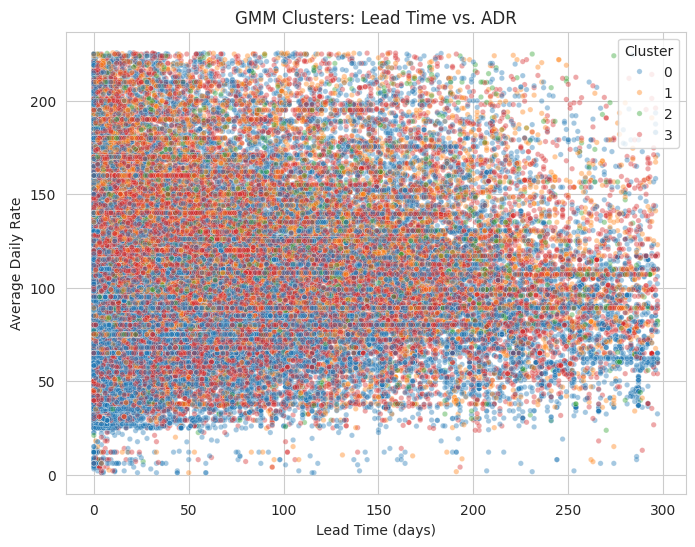

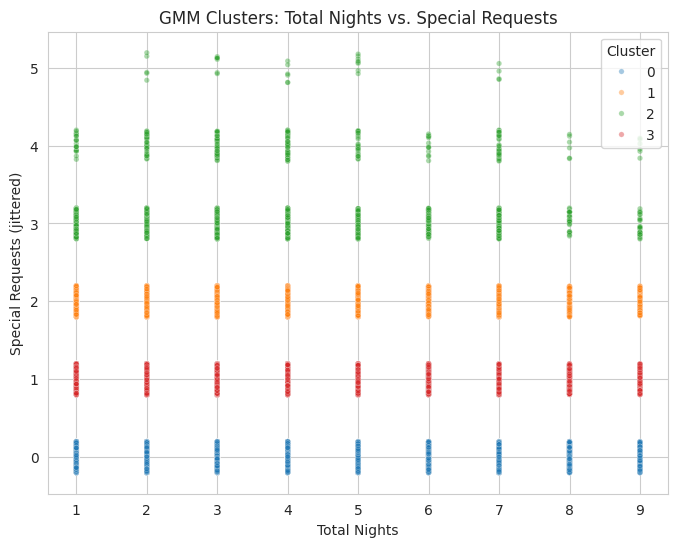

,lead_time,total_nights,adr,total_of_special_requests,guests,pct_of_guests,avg_confidence
gmm_cluster,,,,,,,
0,68.31,3.19,98.47,0.00,39007,50.0,1.0
1,78.04,3.46,115.63,2.00,10481,13.4,1.0
2,86.01,3.73,121.69,3.14,2268,2.9,1.0
3,71.76,3.36,107.32,1.00,26205,33.6,1.0


In [4]:
# Add your code here

gmm = GaussianMixture(n_components=k, random_state=42, n_init=5)
gmm.fit(X_scaled)

probs = gmm.predict_proba(X_scaled)
prob_cols = [f"prob_cluster_{i}" for i in range(k)]
clean[prob_cols] = probs

clean["gmm_cluster"] = probs.argmax(axis=1)
clean["gmm_confidence"] = probs.max(axis=1)

print(clean["gmm_cluster"].value_counts().sort_index())
print(f"Average confidence: {clean['gmm_confidence'].mean():.2f}")
print(f"Guests with confidence < 0.60: {(clean['gmm_confidence'] < 0.60).mean():.1%}")
clean[prob_cols].head()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=clean, x="lead_time", y="adr", hue="gmm_cluster",
                palette="tab10", alpha=0.4, s=15)
plt.title("GMM Clusters: Lead Time vs. ADR")
plt.xlabel("Lead Time (days)")
plt.ylabel("Average Daily Rate")
plt.legend(title="Cluster")
plt.show()

plot_df = clean.copy()
plot_df["requests_jitter"] = plot_df["total_of_special_requests"] + np.random.uniform(-0.2, 0.2, len(plot_df))
plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="total_nights", y="requests_jitter", hue="gmm_cluster",
                palette="tab10", alpha=0.4, s=15)
plt.title("GMM Clusters: Total Nights vs. Special Requests")
plt.xlabel("Total Nights")
plt.ylabel("Special Requests (jittered)")
plt.legend(title="Cluster")
plt.show()

gmm_summary = clean.groupby("gmm_cluster")[features].mean().round(2)
gmm_summary["guests"] = clean["gmm_cluster"].value_counts().sort_index()
gmm_summary["pct_of_guests"] = (gmm_summary["guests"] / len(clean) * 100).round(1)
gmm_summary["avg_confidence"] = clean.groupby("gmm_cluster")["gmm_confidence"].mean().round(2)
gmm_summary

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. KMeans separated guests by several behaviors: lead time, trip length, and price. GMM mostly split them by special requests with other features changing slightly. GMM's 1.0 confidence does not reflect truly distinct groups. KMeans gave clearer, more varied segments for campaigns, while GMM's clusters were uneven and less useful.

2. GMM's soft probabilities suit overlapping behavior. It could help identify guests that are close between two segments. It can also flag niche groups and estimate how likely a guest is to belong to each segment which can help with targeted advertising.


## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
# Add code here 🔧

X = X_scaled.values
km_labels = clean["kmeans_cluster"].values
gmm_labels = clean["gmm_cluster"].values

def wcss(X, labels):
    """Sum of squared distances from each point to its cluster's mean."""
    total = 0
    for c in np.unique(labels):
        pts = X[labels == c]
        total += ((pts - pts.mean(axis=0)) ** 2).sum()
    return total

results = pd.DataFrame({
    "WCSS": [wcss(X, km_labels), wcss(X, gmm_labels)],
    "Silhouette": [
        silhouette_score(X, km_labels, sample_size=10000, random_state=42),
        silhouette_score(X, gmm_labels, sample_size=10000, random_state=42),
    ],
    "Davies-Bouldin": [
        davies_bouldin_score(X, km_labels),
        davies_bouldin_score(X, gmm_labels),
    ],
}, index=["K-Means", "GMM"]).round(3)

results

,WCSS,Silhouette,Davies-Bouldin
K-Means,163648.062,0.247,1.287
GMM,231834.204,0.144,2.507


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans was better on every metric. It had lower WCSS, a higher silhouette score, and a lower Davies-Bouldin Index. Its clusters are tighter and better separated, while GMM's overlap heavily.

5.3. I would recommend KMeans. It scored better with every metric and produces balanced interpretable segments that marketers can target. GMM's clusters mostly reflected special requests and were uneven.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [6]:
# Add code here 🔧

clean["has_children"] = ((clean["children"] + clean["babies"]) > 0).astype(int)
clean["is_resort"] = (clean["hotel"] == "Resort Hotel").astype(int)

profile = clean.groupby("kmeans_cluster").agg(
    guests=("kmeans_cluster", "size"),
    lead_time=("lead_time", "mean"),
    total_nights=("total_nights", "mean"),
    adr=("adr", "mean"),
    special_requests=("total_of_special_requests", "mean"),
    avg_adults=("adults", "mean"),
    pct_with_kids=("has_children", "mean"),
    pct_repeat_guest=("is_repeated_guest", "mean"),
    pct_canceled=("is_canceled", "mean"),
    pct_resort=("is_resort", "mean"),
)

pct_cols = ["pct_with_kids", "pct_repeat_guest", "pct_canceled", "pct_resort"]
profile[pct_cols] = profile[pct_cols] * 100
profile["pct_of_guests"] = profile["guests"] / profile["guests"].sum() * 100

profile = profile.sort_values("adr", ascending=False).round(2)

profile.style.background_gradient(cmap="Blues", axis=0)

,guests,lead_time,total_nights,adr,special_requests,avg_adults,pct_with_kids,pct_repeat_guest,pct_canceled,pct_resort,pct_of_guests
kmeans_cluster,,,,,,,,,,,
3,17672,47.740000,2.960000,152.620000,0.480000,2.020000,15.720000,1.020000,34.510000,26.480000,22.670000
2,11476,68.890000,3.340000,118.770000,2.220000,2.010000,16.150000,3.110000,19.200000,31.510000,14.720000
0,19409,157.880000,5.080000,96.790000,0.510000,1.950000,7.670000,0.480000,35.450000,42.930000,24.900000
1,29404,29.230000,2.310000,74.900000,0.350000,1.690000,3.270000,7.410000,19.480000,39.890000,37.720000


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. Cluster 0: early-planning vacationers, book with most lead time, stay the longest, and skew towards resorts. Cluster 1: solo/couple bargain travelers, they book with the least lead time, have short stays, and pay the least. Cluster 2: service seekers, they make the most requests and pay a high rate. Cluster 3: premium family-leaning guests, they have the most kids, pay the most, and cancel often.

2. Cluster 0: early-bird packages and extended stay offers. Cluster 1: last-minute and weekend deals. Cluster 2: Personalized perks such as room preferences and early check ins. Cluster 3: Family packages and room upgrades with flexible booking.


## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. Without labels, there isn't really a right answer to check against. Choosing k was difficult because the elbow plot had no clear bend and silhouette scores weren't helpful either. I also had to decide whether clusters were actually meaningful.

2. Use clustering when there is no outcome to predict and the goal is discovery, such as finding customer types in a new market or exploring unfamiliar data. Use supervised models when a labeled target exists.

3. Clustering sorts customers into groups that behave alike. Instead of everyone receiving a personal email or ad, each cluster can get a targeted ad based on their behavior/cluster. That translates to better promotions and less money wasted on ad spend.

4. This assignment helped build on Python skills I'd use in auditing such as cleaning data, removing duplicates, and flagging outliers. Clustering also is useful in audit since transactions that sit  far away from every cluster can be targeted for deeper review.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"